# 08 · Capstone: predicting cable overload from household measurements
**Level 3 · Predictive analytics** &nbsp;|&nbsp; Course link: *Module 4 – final exercise: "predict the overloading of a
cable using the power measurements of several households"*

A distribution grid operator (DSO) has smart meters in many homes but **no sensor on most cables**. With electric cars
and heat pumps arriving, some cables will overload. Can we learn, from household power measurements alone, **when a
cable is overloaded**?

**Setting:** SimBench rural low-voltage grid, *future scenario 2034* (heat pumps, more PV), plus an electrification
stress test: **every household owns an electric car with an 11 kW home charger, charged without any control** (people
plug in when they come home). We simulate 8 000 random 15-minute snapshots of the year with full AC power flow. The
simulator provides perfect labels; the models only see what smart meters measure: each home's total power
(household + car) and each PV system's output.

In [1]:
import warnings, json
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn
import pandapower.topology as top, networkx as nx
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.inspection import permutation_importance
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, mean_absolute_error
from energy_ai import snapshots, simbench_grid, ev_charging_probability, get_device, set_seed, style
style(); set_seed(0)
device = get_device()

CODE, LINE = "1-LV-rural2--2-sw", "line15"
d = snapshots(CODE, n=8000, seed=0, ev_share=1.0)
meters = pd.concat([(d["p_load"] + d["p_ev"]), d["p_pv"]], axis=1) * 1000      # what smart meters see [kW]
P = meters
loading = d["line_loading"][LINE]
y = (loading > 100).astype(int)
n_ev = int((d["p_ev"].max() > 0).sum())
print(f"{len(P)} snapshots | {d['p_load'].shape[1]} consumption meters ({n_ev} homes with an EV) + {d['p_pv'].shape[1]} PV meters")
print(f"{LINE} overloaded in {y.mean():.1%} of the snapshots (max loading {loading.max():.0f} %)")

Using device: xpu (Intel(R) UHD Graphics)


8000 snapshots | 118 consumption meters (92 homes with an EV) + 11 PV meters
line15 overloaded in 3.2% of the snapshots (max loading 174 %)


## 1. When and why does the cable overload?

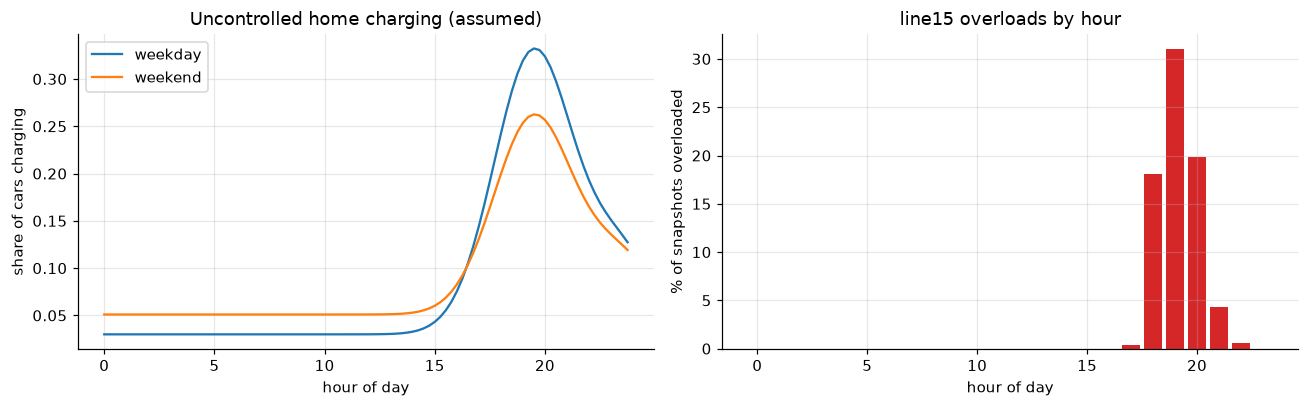

share overloaded by month: {1: 3.6, 2: 3.4, 3: 3.4, 4: 3.5, 5: 1.8, 6: 3.2, 7: 2.6, 8: 3.3, 9: 3.1, 10: 2.4, 11: 2.7, 12: 5.1}


In [2]:
hours = np.arange(0, 24, 0.25)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(hours, ev_charging_probability(pd.date_range("2016-03-07", periods=96, freq="15min")), label="weekday")
ax[0].plot(hours, ev_charging_probability(pd.date_range("2016-03-12", periods=96, freq="15min")), label="weekend")
ax[0].set(xlabel="hour of day", ylabel="share of cars charging", title="Uncontrolled home charging (assumed)"); ax[0].legend()
by_hour = y.groupby(y.index.hour).mean()
ax[1].bar(by_hour.index, 100 * by_hour.values, color="tab:red")
ax[1].set(xlabel="hour of day", ylabel="% of snapshots overloaded", title=f"{LINE} overloads by hour"); plt.tight_layout(); plt.show()
print("share overloaded by month:", (y.groupby(y.index.month).mean() * 100).round(1).to_dict())

## 2. Where is the cable, and who is behind it?
The current in a radial cable is carried by everything **downstream** of it. We find those customers from the grid
topology (as a graph: remove the cable, see which part is cut off from the transformer).

cable line15: NAYY 4x150SE 0.6/1kV, 7 m, rating 270 A | meters downstream: 52 consumers + 5 PV, out of 129


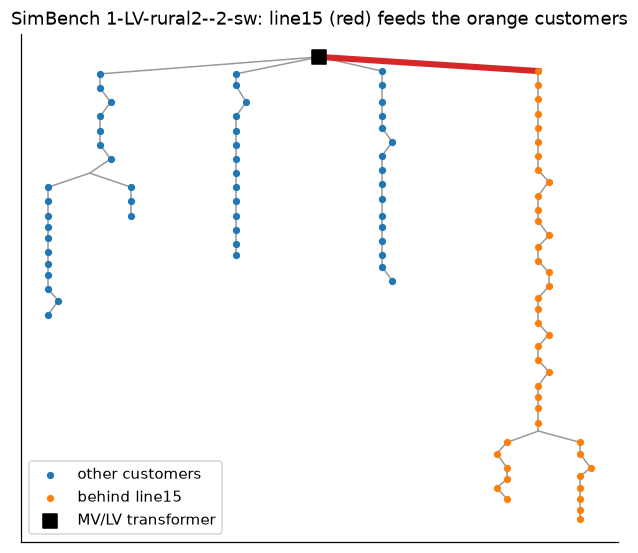

In [3]:
net, _ = simbench_grid(CODE)
line = net.line.loc[int(LINE[4:])]
g = top.create_nxgraph(net, respect_switches=True)
g_cut = g.copy(); g_cut.remove_edge(line.from_bus, line.to_bus)
trafo_bus = net.trafo.lv_bus.iloc[0]
side = line.to_bus if not nx.has_path(g_cut, line.to_bus, trafo_bus) else line.from_bus
down_buses = nx.node_connected_component(g_cut, side)
down_load = [f"load{i}" for i, b in enumerate(net.load.bus) if b in down_buses]
down_pv = [f"pv{i}" for i, b in enumerate(net.sgen.bus) if b in down_buses]
downstream = down_load + down_pv
print(f"cable {LINE}: {line.std_type}, {1000 * line.length_km:.0f} m, rating {1000 * line.max_i_ka:.0f} A | "
      f"meters downstream: {len(down_load)} consumers + {len(down_pv)} PV, out of {P.shape[1]}")

xy = np.array([json.loads(gj)["coordinates"] for gj in net.bus.geo])
fig, ax = plt.subplots(figsize=(7, 6))
for i, ln in net.line.iterrows():
    a, b = xy[ln.from_bus], xy[ln.to_bus]
    hit = i == line.name
    ax.plot([a[0], b[0]], [a[1], b[1]], color="tab:red" if hit else "0.6", lw=4 if hit else 1, zorder=3 if hit else 1)
load_bus = set(net.load.bus)
for bset, c, lab in ((set(net.bus.index) - down_buses, "tab:blue", "other customers"), (down_buses, "tab:orange", f"behind {LINE}")):
    idx = [b for b in bset if b in load_bus]
    ax.scatter(xy[idx, 0], xy[idx, 1], s=14, color=c, label=lab, zorder=4)
ax.scatter(*xy[trafo_bus], marker="s", s=90, color="k", label="MV/LV transformer", zorder=5)
ax.set(title=f"SimBench {CODE}: {LINE} (red) feeds the orange customers", xticks=[], yticks=[]); ax.legend(loc="best"); plt.show()

## 3. Baselines without machine learning
An engineer would estimate the cable current from the **net demand behind the cable** (consumption minus PV) and raise
an alarm above a threshold, tuned on the training data. Without topology knowledge, only the net demand of the whole
grid is available. Train on January–September, test on October–December (a forecast-like split, never random).

In [4]:
t_split = P.index < pd.Timestamp("2016-10-01")
P_tr, P_te, y_tr, y_te = P[t_split], P[~t_split], y[t_split], y[~t_split]
print(f"train: Jan–Sep ({t_split.sum()} snapshots, {y_tr.mean():.1%} overloaded) | test: Oct–Dec ({(~t_split).sum()} snapshots, {y_te.mean():.1%} overloaded)")

def best_threshold_rule(s_tr, s_te):
    ths = np.quantile(s_tr, np.linspace(0.5, 0.999, 300))
    best = max(ths, key=lambda t: f1_score(y_tr, s_tr > t))
    return (s_te > best).astype(int)

def report(name, pred, score=None):
    return {"model": name, "precision": precision_score(y_te, pred), "recall (overloads caught)": recall_score(y_te, pred),
            "F1": f1_score(y_te, pred), "ROC-AUC": roc_auc_score(y_te, score) if score is not None else np.nan,
            "missed overloads": int(((pred == 0) & (y_te == 1)).sum()), "false alarms": int(((pred == 1) & (y_te == 0)).sum())}

pv_cols = list(d["p_pv"].columns)
net_all = lambda X: (X.drop(columns=pv_cols).sum(1) - X[pv_cols].sum(1)).abs()
net_down = lambda X: (X[down_load].sum(1) - X[down_pv].sum(1)).abs()
rows = [report("rule: net demand of the WHOLE grid > threshold", best_threshold_rule(net_all(P_tr), net_all(P_te)), net_all(P_te)),
        report("rule: net demand BEHIND the cable > threshold (needs topology)", best_threshold_rule(net_down(P_tr), net_down(P_te)), net_down(P_te))]
display(pd.DataFrame(rows).set_index("model").round(3))

train: Jan–Sep (5967 snapshots, 3.1% overloaded) | test: Oct–Dec (2033 snapshots, 3.4% overloaded)


,precision,recall (overloads caught),F1,ROC-AUC,missed overloads,false alarms
model,,,,,,
rule: net demand of the WHOLE grid > threshold,0.522,0.870,0.652,0.988,9,55
rule: net demand BEHIND the cable > threshold (needs topology),0.986,0.986,0.986,1.000,1,1


## 4. Machine-learning classifiers (no topology given)
Overloads are rare, so every model is told to weight the minority class (`class_weight="balanced"`, or a weighted loss
for the neural network). Otherwise "never overloaded" would already be >90 % accurate and useless.

In [5]:
class TorchMLPClassifier:
    """Binary MLP classifier on the GPU, weighted cross-entropy for the minority class."""
    def __init__(self, hidden=(128, 64), epochs=200, lr=2e-3):
        self.hidden, self.epochs, self.lr = hidden, epochs, lr
    def fit(self, X, y):
        self.sc = StandardScaler().fit(X)
        Xt = torch.tensor(self.sc.transform(X), dtype=torch.float32, device=device)
        yt = torch.tensor(np.asarray(y)[:, None], dtype=torch.float32, device=device)
        layers, din = [], X.shape[1]
        for h in self.hidden: layers += [nn.Linear(din, h), nn.ReLU(), nn.Dropout(0.1)]; din = h
        self.net = nn.Sequential(*layers, nn.Linear(din, 1)).to(device)
        pos_w = torch.tensor([(1 - yt.mean().item()) / yt.mean().item()], device=device)
        loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_w)
        opt = torch.optim.AdamW(self.net.parameters(), lr=self.lr, weight_decay=1e-4)
        for _ in range(self.epochs):
            self.net.train()
            for b in torch.randperm(len(Xt)).to(device).split(512):
                loss = loss_fn(self.net(Xt[b]), yt[b]); opt.zero_grad(); loss.backward(); opt.step()
        return self
    def predict_proba(self, X):
        self.net.eval()
        with torch.no_grad():
            p = torch.sigmoid(self.net(torch.tensor(self.sc.transform(X), dtype=torch.float32, device=device))).cpu().numpy()[:, 0]
        return np.column_stack([1 - p, p])
    def predict(self, X): return (self.predict_proba(X)[:, 1] > 0.5).astype(int)

models = {
    "logistic regression": make_pipeline(StandardScaler(), LogisticRegression(C=1.0, class_weight="balanced", max_iter=5000)),
    "decision tree": DecisionTreeClassifier(max_depth=8, min_samples_leaf=10, class_weight="balanced", random_state=0),
    "random forest": RandomForestClassifier(n_estimators=400, min_samples_leaf=2, class_weight="balanced", n_jobs=-1, random_state=0),
    "gradient boosting": HistGradientBoostingClassifier(max_iter=500, learning_rate=0.05, class_weight="balanced", random_state=0),
    "neural network (GPU)": TorchMLPClassifier(),
}
for name, m in models.items():
    m.fit(P_tr, y_tr)
    s = m.predict_proba(P_te)[:, 1]
    rows.append(report(name, (s > 0.5).astype(int), s))
res = pd.DataFrame(rows).set_index("model")
display(res.round(3))

,precision,recall (overloads caught),F1,ROC-AUC,missed overloads,false alarms
model,,,,,,
rule: net demand of the WHOLE grid > threshold,0.522,0.870,0.652,0.988,9,55
rule: net demand BEHIND the cable > threshold (needs topology),0.986,0.986,0.986,1.000,1,1
logistic regression,0.882,0.971,0.924,0.999,2,9
decision tree,0.175,0.696,0.280,0.813,21,226
random forest,0.615,0.116,0.195,0.967,61,5
gradient boosting,0.897,0.377,0.531,0.988,43,3
neural network (GPU),0.831,0.783,0.806,0.994,15,11


**Reading the table**
* With the topology known, a one-line physics rule is almost perfect: the cable current *is* the net demand behind it.
* Without topology, **logistic regression** is the best learner. The trees have a high ROC-AUC (they *rank* the cases
  well) but miss most overloads at the default 0.5 threshold. The reason is the shape of the physics: the cable current
  is a **weighted sum of ~57 household powers**. A linear model represents a sum exactly; a tree approximates it with
  axis-aligned steps and would need far more than the ~190 overload examples in the training data.
* Lesson: choose a model whose structure (inductive bias) matches the physics, and for rare events judge models by
  recall/precision at a tuned threshold, not by accuracy.

## 5. Did the model discover the grid topology?
Permutation importance: how much does the F1 score drop when one meter's readings are shuffled? If the model learned
the physics, the important meters are the ones **behind the cable**, although it was never told the topology.

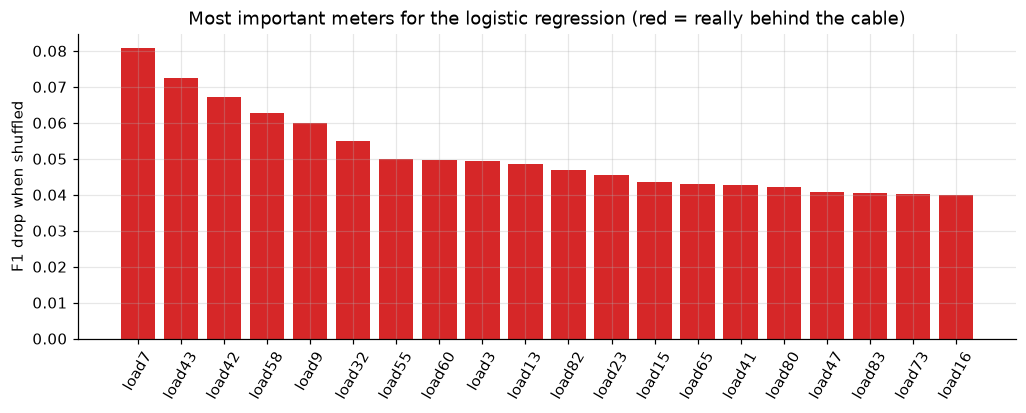

best model: logistic regression | of its 57 most important meters, 43 are behind line15


In [6]:
best_name = res.drop(index=[r for r in res.index if r.startswith("rule")])["F1"].idxmax()
best = models[best_name]
pi = permutation_importance(best, P_te, y_te, scoring="f1", n_repeats=5, random_state=0, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=P.columns).sort_values(ascending=False)
top20 = imp.head(20)
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.bar(top20.index, top20.values, color=["tab:red" if c in downstream else "tab:grey" for c in top20.index])
ax.set(title=f"Most important meters for the {best_name} (red = really behind the cable)", ylabel="F1 drop when shuffled")
plt.xticks(rotation=60); plt.show()
k = len(downstream)
print(f"best model: {best_name} | of its {k} most important meters, {sum(c in downstream for c in imp.index[:k])} are behind {LINE}")

## 6. How many smart meters do we need?
Not every home has a smart meter. We retrain with only *m* randomly chosen meters (5 random draws per size).

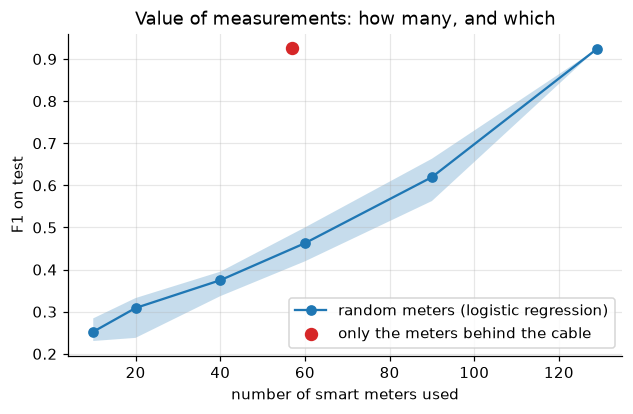

,meters,F1 mean,F1 min,F1 max
0,10,0.253,0.230,0.284
1,20,0.309,0.238,0.332
2,40,0.375,0.337,0.395
3,60,0.463,0.420,0.500
4,90,0.620,0.563,0.663
5,129,0.924,0.924,0.924


F1 using only the 57 meters behind the cable: 0.925


In [7]:
rng = np.random.default_rng(0)
curve = []
for m in (10, 20, 40, 60, 90, P.shape[1]):
    f1s = []
    for rep in range(5):
        cols = rng.choice(P.columns, size=m, replace=False)
        mdl = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=5000)).fit(P_tr[cols], y_tr)
        f1s.append(f1_score(y_te, mdl.predict(P_te[cols])))
    curve.append({"meters": m, "F1 mean": np.mean(f1s), "F1 min": np.min(f1s), "F1 max": np.max(f1s)})
curve = pd.DataFrame(curve)
only_down = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=5000)).fit(P_tr[downstream], y_tr)
f1_down = f1_score(y_te, only_down.predict(P_te[downstream]))
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(curve.meters, curve["F1 mean"], "o-", label="random meters (logistic regression)")
ax.fill_between(curve.meters, curve["F1 min"], curve["F1 max"], alpha=0.25)
ax.scatter([len(downstream)], [f1_down], color="tab:red", zorder=5, s=60, label="only the meters behind the cable")
ax.set(xlabel="number of smart meters used", ylabel="F1 on test", title="Value of measurements: how many, and which"); ax.legend(); plt.show()
display(curve.round(3))
print(f"F1 using only the {len(downstream)} meters behind the cable: {f1_down:.3f}")

## 7. Beyond yes/no: predicting the loading itself
A regression model predicts the loading in %, which tells the operator *how close* to the limit the cable is.
Same comparison as above: a linear model versus gradient-boosted trees.

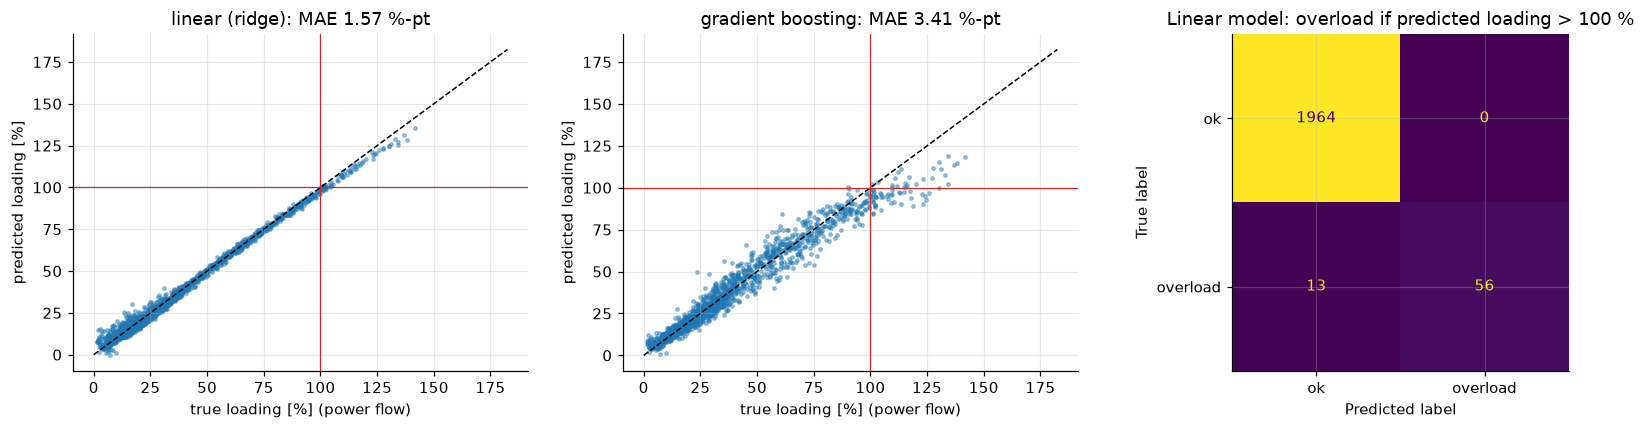

In [8]:
from sklearn.linear_model import Ridge
regs = {"linear (ridge)": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
        "gradient boosting": HistGradientBoostingRegressor(max_iter=600, learning_rate=0.05, random_state=0)}
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, (name, r) in zip(ax[:2], regs.items()):
    lp = r.fit(P_tr, loading[t_split]).predict(P_te)
    a.scatter(loading[~t_split], lp, s=5, alpha=0.4); lim = [0, loading.max() * 1.05]; a.plot(lim, lim, "k--", lw=1)
    a.axvline(100, color="tab:red", lw=0.8); a.axhline(100, color="tab:red", lw=0.8)
    a.set(xlabel="true loading [%] (power flow)", ylabel="predicted loading [%]",
          title=f"{name}: MAE {mean_absolute_error(loading[~t_split], lp):.2f} %-pt")
    if name.startswith("linear"): lp_lin = lp
ConfusionMatrixDisplay(confusion_matrix(y_te, (lp_lin > 100).astype(int)), display_labels=["ok", "overload"]).plot(ax=ax[2], colorbar=False)
ax[2].set_title("Linear model: overload if predicted loading > 100 %"); plt.tight_layout(); plt.show()

## Key takeaways
* Smart-meter data alone is enough to detect when a cable is overloaded, without a sensor on the cable.
* The physics is simple here (cable current ≈ net demand behind it), so **simple models are hard to beat**: a linear
  model learns it without topology, while tree ensembles struggle with sums and saturate at the extremes (they cannot
  predict values beyond those seen in training).
* ML's real contribution is finding *which* meters matter without being told the topology.
* Measurements behind the cable carry the information: the meters behind the cable alone match all 129 meters, while
  the same number of randomly chosen meters is far worse.
* In practice you would forecast the meter readings (notebooks 05–06) and feed them to this model for an **early
  warning**, then avoid the overload with flexibility such as smart charging (notebooks 11 and 15).